# Waimea WaveCast — Near Real-Time API Test

**Kiểm thử thứ tự:** **CDIP 106 (quan trắc)** → **NOAA 51201 (quan trắc dự phòng)** → **Open-Meteo Marine (mô hình dự báo)**.

Mục tiêu notebook:

1. Gọi cả 3 nguồn để so sánh công khai dữ liệu mới nhất tại mỗi lần kiểm tra.
2. In riêng **thời điểm truy vấn**, **thời điểm quan trắc / thời điểm hợp lệ của mô hình**, và **độ cũ của bản ghi**.
3. Chọn nguồn theo ưu tiên có kiểm tra độ mới; **không biến dự báo mô hình thành số đo thật**.
4. Tùy chọn chạy polling có giới hạn; phát hiện khi nguồn xuất hiện bản ghi mới và xuất log CSV.
5. Khi CDIP lỗi, notebook vẫn tiếp tục NOAA và Open-Meteo, đồng thời lưu nội dung phản hồi CDIP để debug.

> **Quan trọng:** không có API công cộng nào trong bài kiểm thử này cam kết bản ghi phao xuất hiện đúng phút mong muốn. CDIP và NOAA đều cung cấp dữ liệu liên quan đến **cùng phao**. Thời gian của từng hệ thống có thể đại diện các mốc khác nhau của kỳ đo; không suy luận tốc độ công bố chỉ từ chênh lệch timestamp.

**Nguồn tài liệu:** [CDIP NDAR](https://cdip.ucsd.edu/data_access/ndar.cdip), [CDIP Data Access FAQ](https://cdip.ucsd.edu/?map_stati=1&nav=documents&pub=public&stn=147&stream=p1&sub=faq&xitem=access), [NOAA 51201 TXT](https://www.ndbc.noaa.gov/data/realtime2/51201.txt), [Open-Meteo Marine](https://open-meteo.com/en/docs/marine-weather-api).

In [13]:
# Chạy cell này một lần, sau đó chọn lại kernel nếu môi trường yêu cầu.
%pip install -q requests pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Cấu hình

- `MAX_OBSERVATION_AGE_MIN`: ngưỡng **độ cũ tính từ timestamp quan trắc**, *không phải* độ trễ công bố; mặc định 120 phút để kiểm tra cả khi phao chậm.
- `MONITOR_ENABLED=False`: notebook **không tự chờ lâu** khi chọn Run All. Đổi thành `True` tại bước 5 để thử theo dõi nhiều chu kỳ.
- `POLL_INTERVAL_SECONDS`: khoảng chờ giữa hai lần kiểm tra (gợi ý 120 giây), không nên gọi liên tục ở mức vài giây.
- Mọi thời gian nội bộ được lưu theo **UTC**; có thêm cột giờ Việt Nam và Hawaii để đối chiếu.

In [21]:
from __future__ import annotations

import io
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests
from IPython.display import display

# Cấu hình Waimea Bay
CDIP_STATION = "106"
NOAA_STATION = "51201"
LAT, LON = 21.671, -158.118
MAX_OBSERVATION_AGE_MIN = 120
REQUEST_TIMEOUT_SECONDS = 25

# Polling: chỉ dùng thử nghiệm, không phải cron/scheduler production.
MONITOR_ENABLED = False
MONITOR_CYCLES = 16              # 16 lần, cách nhau 2 phút ~ 30 phút
POLL_INTERVAL_SECONDS = 120

OUTPUT = Path("waimea_realtime_test")
OUTPUT.mkdir(exist_ok=True)

CDIP_NDAR_URL = f"https://cdip.ucsd.edu/data_access/ndar.cdip?{CDIP_STATION}+pm+1+h"
CDIP_JUSTDAR_URL = f"https://cdip.ucsd.edu/data_access/justdar.cdip?{CDIP_STATION}+pm+1"
NOAA_URL = f"https://www.ndbc.noaa.gov/data/realtime2/{NOAA_STATION}.txt"
OPEN_METEO_URL = "https://marine-api.open-meteo.com/v1/marine"

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "WaimeaWaveCast-educational-api-test/1.0", "Accept": "text/plain, application/json, */*"})

print("CDIP:", CDIP_NDAR_URL)
print("NOAA:", NOAA_URL)
print("Open-Meteo:", OPEN_METEO_URL)

CDIP: https://cdip.ucsd.edu/data_access/ndar.cdip?106+pm+1+h
NOAA: https://www.ndbc.noaa.gov/data/realtime2/51201.txt
Open-Meteo: https://marine-api.open-meteo.com/v1/marine


## 2. Hàm xử lý chung

`http_get` thực hiện một request có timeout. Để dễ so sánh độ trễ, notebook không tự ẩn nhiều lần retry. Các lỗi được ghi vào bảng kết quả; thông số **`age_minutes` đo thời gian từ timestamp bản ghi tới lúc nhận API**, không phải thời gian truyền/công bố thực sự.

In [15]:
def utc_now():
    return pd.Timestamp.now(tz="UTC")


def iso_utc(value):
    if value is None or pd.isna(value):
        return None
    return pd.Timestamp(value).tz_convert("UTC").isoformat()


def valid_number(value, lower=None, upper=None):
    try:
        if value is None or str(value).strip().upper() in {"", "MM", "NAN", "NONE", "NULL"}:
            return None
        f = float(value)
        if not pd.notna(f):
            return None
        if (lower is not None and f < lower) or (upper is not None and f > upper):
            return None
        return f
    except (ValueError, TypeError):
        return None


def age_minutes(when, now=None):
    if when is None or pd.isna(when):
        return None
    now = now if now is not None else utc_now()
    return round((now - pd.Timestamp(when)).total_seconds() / 60, 2)


def http_get(url, params=None):
    start = time.perf_counter()
    response = SESSION.get(url, params=params, timeout=REQUEST_TIMEOUT_SECONDS)
    elapsed_ms = round((time.perf_counter() - start) * 1000)
    fetched_at = utc_now()
    response.raise_for_status()
    return response, fetched_at, elapsed_ms


def row_template(source, data_type="observation"):
    return {
        "source": source,
        "data_type": data_type,
        "status": "error",
        "fetched_at_utc": None,
        "data_time_utc": None,
        "age_minutes": None,
        "wave_height_m": None,
        "wave_period_s": None,
        "wave_direction_deg": None,
        "sea_surface_temperature_c": None,
        "request_ms": None,
        "endpoint": None,
        "note": None,
    }


def filled_row(source, data_type, fetched_at, data_time, elapsed_ms, endpoint, **values):
    r = row_template(source, data_type)
    r.update({
        "status": "ok",
        "fetched_at_utc": iso_utc(fetched_at),
        "data_time_utc": iso_utc(data_time),
        "age_minutes": age_minutes(data_time, fetched_at),
        "request_ms": elapsed_ms,
        "endpoint": endpoint,
    })
    r.update(values)
    return r


def to_local_time(text, timezone_name):
    if not text:
        return None
    return pd.Timestamp(text).tz_convert(timezone_name).strftime("%Y-%m-%d %H:%M:%S %Z")

## 3. Adapter CDIP 106 — quan trắc ưu tiên

Dùng **NDAR định dạng `pm`**, không cần `netCDF4`. Nếu NDAR báo lỗi hoặc không có hàng hợp lệ, notebook thử `justdar` và ghi lại bản phản hồi vào file debug.

Trong định dạng `pm` cổ điển, 5 cột đầu là `year month day hour minute`, cột thứ 6 là **Hs (m)**, cột thứ 7 **Tp (s)**, cột thứ 8 **Dp (°)**. Nếu nguồn thay đổi định dạng, parser báo lỗi thay vì tự gán sai dữ liệu. Dữ liệu thời gian của CDIP có thể là thời điểm **bắt đầu kỳ quan trắc**.

In [16]:
def parse_cdip_pm(text):
    if not text.strip() or text.lstrip().lower().startswith(("<!doctype", "<html")):
        raise ValueError("CDIP trả HTML/rỗng thay vì dữ liệu PM")

    rows = []
    for line in text.splitlines():
        fields = re.split(r"\s+", line.strip())
        if len(fields) < 6 or not re.fullmatch(r"(?:19|20)\d{2}", fields[0]):
            continue
        try:
            parts = [int(v) for v in fields[:5]]
            stamp = pd.Timestamp(datetime(*parts, tzinfo=timezone.utc))
        except (ValueError, TypeError):
            continue
        # Kiểm tra miền thời gian trước khi đọc các cột vật lý.
        if stamp > utc_now() + pd.Timedelta(minutes=10) or stamp.year < 1990:
            continue
        h = valid_number(fields[5], lower=0, upper=40)
        if h is None:
            continue
        rows.append({
            "timestamp": stamp,
            "wave_height_m": h,
            "wave_period_s": valid_number(fields[6], lower=0.1, upper=100) if len(fields) > 6 else None,
            "wave_direction_deg": valid_number(fields[7], lower=0, upper=360) if len(fields) > 7 else None,
        })
    if not rows:
        raise ValueError("Không tìm thấy bản ghi PM hợp lệ (YYYY MM DD HH mm Hs ...)")
    return max(rows, key=lambda r: r["timestamp"]), len(rows)


def fetch_cdip():
    errors = []
    for label, url in [("NDAR", CDIP_NDAR_URL), ("Justdar", CDIP_JUSTDAR_URL)]:
        try:
            response, fetched, elapsed = http_get(url)
            (OUTPUT / "cdip_last_response.txt").write_text(response.text[:30000], encoding="utf-8")
            sample, count = parse_cdip_pm(response.text)
            return filled_row(
                "CDIP 106", "observation", fetched, sample["timestamp"], elapsed, response.url,
                wave_height_m=sample["wave_height_m"],
                wave_period_s=sample["wave_period_s"],
                wave_direction_deg=sample["wave_direction_deg"],
                note=f"{label}: đọc {count} bản ghi PM; timestamp có thể là đầu kỳ đo",
            )
        except (requests.RequestException, ValueError, UnicodeError, OSError) as exc:
            errors.append(f"{label}: {type(exc).__name__}: {str(exc)[:220]}")
    r = row_template("CDIP 106")
    r["note"] = " | ".join(errors)
    return r

## 4. Adapter NOAA 51201 — quan trắc dự phòng

NOAA `/data/realtime2/51201.txt` có 2 dòng header, tiếp theo là những hàng dữ liệu. Đọc tên cột từ header thật để không phụ thuộc vào vị trí cố định của các cột `WVHT`, `DPD`, `MWD`, `WTMP`. `MM` là thiếu dữ liệu.

In [17]:
def parse_noaa_txt(text):
    lines = text.splitlines()
    if len(lines) < 3 or not lines[0].lstrip().startswith("#"):
        raise ValueError("NOAA TXT không có header hợp lệ")

    columns = lines[0].lstrip("# ").split()
    records = []
    for line in lines[2:]:
        parts = line.split()
        if len(parts) != len(columns):
            continue
        rec = dict(zip(columns, parts))
        try:
            year = int(rec.get("YY", rec.get("YYYY")))
            if year < 100:
                year += 2000 if year < 70 else 1900
            stamp = pd.Timestamp(datetime(
                year, int(rec["MM"]), int(rec["DD"]),
                int(rec["hh"]), int(rec["mm"]), tzinfo=timezone.utc
            ))
        except (ValueError, KeyError, TypeError):
            continue
        h = valid_number(rec.get("WVHT"), lower=0, upper=40)
        if h is None:
            continue
        records.append({
            "timestamp": stamp,
            "wave_height_m": h,
            "wave_period_s": valid_number(rec.get("DPD"), lower=0.1, upper=100),
            "wave_direction_deg": valid_number(rec.get("MWD"), lower=0, upper=360),
            "sea_surface_temperature_c": valid_number(rec.get("WTMP"), lower=-3, upper=45),
        })
    if not records:
        raise ValueError("Không tìm thấy bản ghi NOAA có WVHT hợp lệ")
    return max(records, key=lambda r: r["timestamp"]), len(records)


def fetch_noaa():
    try:
        response, fetched, elapsed = http_get(NOAA_URL)
        sample, count = parse_noaa_txt(response.text)
        return filled_row(
            "NOAA 51201", "observation", fetched, sample["timestamp"], elapsed, response.url,
            wave_height_m=sample["wave_height_m"],
            wave_period_s=sample["wave_period_s"],
            wave_direction_deg=sample["wave_direction_deg"],
            sea_surface_temperature_c=sample["sea_surface_temperature_c"],
            note=f"Đọc {count} hàng có WVHT hợp lệ trong TXT",
        )
    except (requests.RequestException, ValueError, UnicodeError, OSError) as exc:
        r = row_template("NOAA 51201")
        r["note"] = f"{type(exc).__name__}: {str(exc)[:300]}"
        return r

## 5. Adapter Open-Meteo — mô hình, **không phải phao**

Dùng `current` để lấy mốc mô hình gần hiện tại. Dữ liệu `current.time` là **thời điểm hiệu lực của giá trị mô hình**, không phải timestamp đo của thiết bị và không phải thời điểm mô hình vừa cập nhật. Gọi cả `hourly` để xem một vài giờ gần hiện tại và tương lai.

In [18]:
OPEN_METEO_VARIABLES = (
    "wave_height,wave_period,wave_direction,"
    "swell_wave_height,sea_surface_temperature"
)


def fetch_open_meteo():
    params = {
        "latitude": LAT,
        "longitude": LON,
        "current": OPEN_METEO_VARIABLES,
        "hourly": OPEN_METEO_VARIABLES,
        "past_hours": 3,
        "forecast_hours": 7,
        "timezone": "UTC",
        "cell_selection": "sea",
    }
    try:
        response, fetched, elapsed = http_get(OPEN_METEO_URL, params=params)
        data = response.json()
        if data.get("error"):
            raise ValueError(data.get("reason", "Open-Meteo trả lỗi JSON"))
        current = data.get("current") or {}
        if not current.get("time"):
            raise ValueError("Không có current.time trong phản hồi Open-Meteo")
        time_utc = pd.Timestamp(current["time"], tz="UTC")
        h = valid_number(current.get("wave_height"), lower=0, upper=40)
        if h is None:
            raise ValueError("Open-Meteo không trả current.wave_height hợp lệ")
        hourly = data.get("hourly", {})
        if hourly.get("time"):
            frame = pd.DataFrame(hourly)
            frame.to_csv(OUTPUT / "open_meteo_hourly.csv", index=False)
        return filled_row(
            "Open-Meteo", "model", fetched, time_utc, elapsed, response.url,
            wave_height_m=h,
            wave_period_s=valid_number(current.get("wave_period"), lower=0.1, upper=100),
            wave_direction_deg=valid_number(current.get("wave_direction"), lower=0, upper=360),
            sea_surface_temperature_c=valid_number(current.get("sea_surface_temperature"), lower=-3, upper=45),
            note="Mô hình current (không phải số đo); hourly CSV có thêm các mốc dự báo",
        )
    except (requests.RequestException, ValueError, KeyError, TypeError) as exc:
        r = row_template("Open-Meteo", "model")
        r["note"] = f"{type(exc).__name__}: {str(exc)[:300]}"
        return r

## 6. Gọi từng nguồn, chọn fallback và theo dõi bản ghi mới

Logic chọn nguồn:

- CDIP `ok` + dữ liệu không quá ngưỡng cũ → ưu tiên **CDIP**; nếu NOAA có timestamp mới hơn CDIP ít nhất 30 phút, tạm chọn **NOAA** (heuristic cần kiểm tra ý nghĩa timestamp).
- Nếu không → NOAA `ok` + đủ mới → chọn **NOAA**.
- Nếu không → lấy **Open-Meteo**, gắn nhãn `MODEL (NOT OBSERVED)`.
- Nếu cả ba lỗi → báo **NO DATA**.

Đồng thời, bảng so sánh **vẫn hiển thị cả CDIP và NOAA** để bạn kiểm tra nguồn nào xuất hiện bản ghi sớm hơn. `first_seen_utc` là thời điểm notebook lần đầu phát hiện bản ghi trong **phiên thử hiện tại**, không phải thời điểm nhà cung cấp công bố. Dữ liệu còn lại không được tự điền bằng giá trị mô hình.

In [19]:
HISTORY = []
SEEN_TIMESTAMPS = {}      # So sánh thay đổi giữa các lần poll trong phiên notebook
FIRST_SEEN_LOG = []


def is_recent_observation(row):
    return (
        row["status"] == "ok"
        and row["data_type"] == "observation"
        and row["age_minutes"] is not None
        and -5 <= row["age_minutes"] <= MAX_OBSERVATION_AGE_MIN
        and row["wave_height_m"] is not None
    )


def choose_source(rows):
    by_name = {r["source"]: r for r in rows}
    cdip = by_name["CDIP 106"]
    noaa = by_name["NOAA 51201"]
    # Do CDIP/NOAA có thể gắn nhãn timestamp ở các mốc khác nhau của kỳ đo,
    # chỉ ghi đè ưu tiên CDIP khi NOAA mới hơn RÕ RỆT (>= 30 phút).
    # Đây là heuristic phục vụ thử nghiệm, không phải khẳng định hai kỳ đo tương đương.
    if is_recent_observation(cdip) and is_recent_observation(noaa):
        if cdip["age_minutes"] - noaa["age_minutes"] >= 30:
            return "NOAA 51201", "OBSERVATION"
        return "CDIP 106", "OBSERVATION"
    if is_recent_observation(cdip):
        return "CDIP 106", "OBSERVATION"
    if is_recent_observation(noaa):
        return "NOAA 51201", "OBSERVATION"
    if by_name["Open-Meteo"]["status"] == "ok":
        return "Open-Meteo", "MODEL (NOT OBSERVED)"
    return None, "NO DATA"


def run_probe():
    started = utc_now()
    print(f"\n=== KIỂM TRA: {started.strftime('%Y-%m-%d %H:%M:%S UTC')} ===")
    rows = [fetch_cdip(), fetch_noaa(), fetch_open_meteo()]
    chosen, chosen_type = choose_source(rows)
    for row in rows:
        source = row["source"]
        current_stamp = row["data_time_utc"] if row["status"] == "ok" else None
        previous_stamp = SEEN_TIMESTAMPS.get(source)
        if current_stamp:
            if source not in SEEN_TIMESTAMPS:
                status_change = "INITIAL"
            elif previous_stamp != current_stamp:
                status_change = "NEW"
            else:
                status_change = "SAME"
            if status_change in ("INITIAL", "NEW"):
                FIRST_SEEN_LOG.append({
                    "source": source,
                    "data_time_utc": current_stamp,
                    "first_seen_utc": row["fetched_at_utc"],
                    "status_change": status_change,
                    "type": row["data_type"],
                })
            SEEN_TIMESTAMPS[source] = current_stamp
        else:
            status_change = "ERROR"
        row["poll_started_utc"] = iso_utc(started)
        row["change"] = status_change
        row["selected"] = row["source"] == chosen
        HISTORY.append(row.copy())

    df = pd.DataFrame(rows)
    columns = ["source", "data_type", "status", "change", "data_time_utc",
               "fetched_at_utc", "age_minutes", "wave_height_m", "wave_period_s",
               "wave_direction_deg", "sea_surface_temperature_c", "request_ms", "selected"]
    display(df[columns])
    print("Nguồn được chọn:", chosen or "Không có", "|", chosen_type)
    if chosen_type == "MODEL (NOT OBSERVED)":
        print("CẢNH BÁO: đây là dự báo/mô hình, KHÔNG phải quan trắc thực tế!")
    for row in rows:
        if row["status"] != "ok":
            print("Lỗi", row["source"], ":", row["note"])
    return df

## 7. Kiểm tra ngay — chạy cell này

Cell gọi cả ba nguồn một lần và hiển thị kết quả theo UTC. Nếu CDIP gặp lỗi, xem `waimea_realtime_test/cdip_last_response.txt` (nếu phản hồi HTTP 200 nhưng không đọc được).

In [20]:
latest_results = run_probe()

# Hiển thị thêm giờ Việt Nam và giờ Hawaii để tránh hiểu nhầm ngày UTC.
time_comparison = latest_results[["source", "data_time_utc", "age_minutes", "change"]].copy()
time_comparison["giờ_Việt_Nam"] = time_comparison["data_time_utc"].map(
    lambda s: to_local_time(s, "Asia/Ho_Chi_Minh")
)
time_comparison["giờ_Hawaii"] = time_comparison["data_time_utc"].map(
    lambda s: to_local_time(s, "Pacific/Honolulu")
)
display(time_comparison)


=== KIỂM TRA: 2026-10-30 07:46:23 UTC ===


,source,data_type,status,change,data_time_utc,fetched_at_utc,age_minutes,wave_height_m,wave_period_s,wave_direction_deg,sea_surface_temperature_c,request_ms,selected
0,CDIP 106,observation,error,ERROR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,NOAA 51201,observation,ok,INITIAL,2026-10-30T06:56:00+00:00,2026-10-30T07:46:23.979360+00:00,50.40,1.60,11.0,22.0,26.1,91.0,True
2,Open-Meteo,model,ok,INITIAL,2026-10-30T07:45:00+00:00,2026-10-30T07:46:24.909161+00:00,1.42,1.74,9.0,46.0,26.0,904.0,False


Nguồn được chọn: NOAA 51201 | OBSERVATION
Lỗi CDIP 106 : NDAR: HTTPError: 403 Client Error: Forbidden for url: https://cdip.ucsd.edu/data_access/ndar.cdip?106+pm+1+h | Justdar: HTTPError: 403 Client Error: Forbidden for url: https://cdip.ucsd.edu/data_access/justdar.cdip?106+pm+1


ValueError: NaTType does not support strftime

## 8. Theo dõi nhiều chu kỳ — **tùy chọn**

Để kiểm tra nguồn có bản ghi mới sau khoảng 30 phút hay không, đổi `MONITOR_ENABLED = True` ở cell dưới và chạy. Mặc định: **16 lần kiểm tra, cách nhau 120 giây**, chỉ dùng để thí nghiệm. Mỗi vòng gọi **CDIP NDAR/Justdar, NOAA và Open-Meteo**; không nên chạy liên tục không giới hạn. Bấm nút **Interrupt Kernel** để dừng sớm.

**Lưu ý:** HTTP 200 không đồng nghĩa có bản ghi mới; kiểm tra cột `change == NEW`. Gọi mỗi 2 phút chỉ xác định thời điểm *notebook phát hiện*, không đo được chính xác thời điểm máy chủ đã công bố dữ liệu.

In [ ]:
# THAY False BẰNG True NẾU MUỐN THEO DÕI.
MONITOR_ENABLED = False

if MONITOR_ENABLED:
    if MONITOR_CYCLES < 1 or POLL_INTERVAL_SECONDS < 60:
        raise ValueError("Chỉ chạy tối thiểu 60 giây/lần và ít nhất 1 chu kỳ")
    try:
        for cycle in range(MONITOR_CYCLES):
            print(f"\n===== VÒNG {cycle + 1}/{MONITOR_CYCLES} =====")
            run_probe()
            pd.DataFrame(HISTORY).to_csv(OUTPUT / "poll_history.csv", index=False)
            pd.DataFrame(FIRST_SEEN_LOG).to_csv(OUTPUT / "first_seen.csv", index=False)
            if cycle + 1 < MONITOR_CYCLES:
                time.sleep(POLL_INTERVAL_SECONDS)
    except KeyboardInterrupt:
        print("Đã dừng polling theo yêu cầu")
else:
    print("Chế độ theo dõi chưa bật. Đổi MONITOR_ENABLED=True rồi chạy lại cell này.")

Chế độ theo dõi chưa bật. Đổi MONITOR_ENABLED=True rồi chạy lại cell này.


## 9. Xuất CSV, kiểm tra bản ghi mới và trực quan hóa

- `poll_history.csv`: một dòng cho mỗi nguồn ở mỗi lần truy vấn (gồm cả lỗi).
- `first_seen.csv`: thời điểm notebook lần đầu nhìn thấy một timestamp, theo phiên làm việc hiện tại.
- `open_meteo_hourly.csv`: dữ liệu mô hình quá khứ/hiện tại/tương lai.

**Đừng dùng `first_seen - data_time` để khẳng định SLA công bố 1–3 phút**, vì `data_time` có thể là mốc bắt đầu chu kỳ đo.

In [ ]:
history_df = pd.DataFrame(HISTORY)
first_seen_df = pd.DataFrame(FIRST_SEEN_LOG)

if not history_df.empty:
    history_df.to_csv(OUTPUT / "poll_history.csv", index=False)
    display(history_df[["source", "poll_started_utc", "data_time_utc", "change", "age_minutes", "selected"]].tail(18))
if not first_seen_df.empty:
    first_seen_df.to_csv(OUTPUT / "first_seen.csv", index=False)
    display(first_seen_df.tail(12))

print("Đã lưu các kết quả trong:", OUTPUT.resolve())

,source,poll_started_utc,data_time_utc,change,age_minutes,selected
0,CDIP 106,2026-10-30T07:45:23.990677+00:00,NaN,ERROR,NaN,False
1,NOAA 51201,2026-10-30T07:45:23.990677+00:00,2026-10-30T06:56:00+00:00,INITIAL,49.43,True
2,Open-Meteo,2026-10-30T07:45:23.990677+00:00,2026-10-30T07:45:00+00:00,INITIAL,0.46,False


,source,data_time_utc,first_seen_utc,status_change,type
0,NOAA 51201,2026-10-30T06:56:00+00:00,2026-10-30T07:45:25.844813+00:00,INITIAL,observation
1,Open-Meteo,2026-10-30T07:45:00+00:00,2026-10-30T07:45:27.471243+00:00,INITIAL,model


Đã lưu các kết quả trong: E:\23115053122114_K23_PhanVanKhanh\College_Year04\126\Kho-du-lieu\repo\waimea_realtime_test


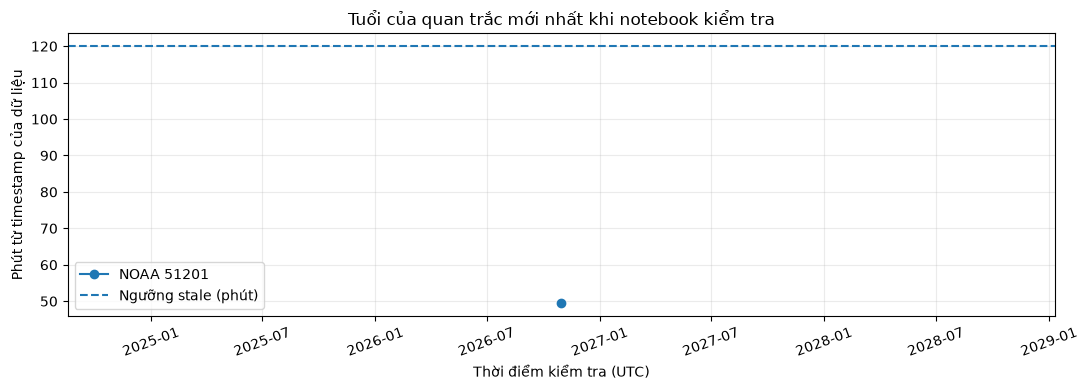

In [ ]:
# Biểu đồ độ cũ của timestamp qua mỗi lần kiểm tra; loại dữ liệu mô hình tách biệt.
import matplotlib.pyplot as plt

obs = history_df[(history_df["data_type"] == "observation") &
                 (history_df["status"] == "ok")].copy()
if not obs.empty:
    obs["checked_at"] = pd.to_datetime(obs["poll_started_utc"], utc=True)
    fig, ax = plt.subplots(figsize=(11, 4))
    for name, group in obs.groupby("source"):
        ax.plot(group["checked_at"], group["age_minutes"], marker="o", label=name)
    ax.axhline(MAX_OBSERVATION_AGE_MIN, linestyle="--", label="Ngưỡng stale (phút)")
    ax.set(title="Tuổi của quan trắc mới nhất khi notebook kiểm tra",
           xlabel="Thời điểm kiểm tra (UTC)", ylabel="Phút từ timestamp của dữ liệu")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có quan trắc thành công để vẽ biểu đồ.")

## 10. Cách đọc kết quả

| Trường | Ý nghĩa |
|---|---|
| `data_time_utc` | CDIP/NOAA: timestamp gắn với số đo; Open-Meteo: thời điểm hiệu lực của mô hình |
| `fetched_at_utc` | Thời điểm máy bạn nhận xong phản hồi HTTP |
| `age_minutes` | Tuổi của timestamp, không phải độ trễ công bố |
| `change` | `INITIAL`: lần đầu thấy; `NEW`: khác lần trước; `SAME`: chưa đổi; `ERROR`: request/parser lỗi |
| `selected` | Nguồn được pipeline đề xuất chọn cho lần kiểm tra này |

**Nếu lúc 06:57 mà chưa có bản ghi 06:56:** bảng sẽ hiện `SAME` hoặc lỗi nguồn; hệ thống không được tự tạo số đo. Khi nguồn công bố, lần polling tiếp theo sẽ phát hiện `NEW`.

**Lưu ý so sánh CDIP ↔ NOAA:** hai luồng thuộc cùng phao, nhưng timestamp có thể ghi dấu các mốc khác nhau của kỳ đo; muốn kết luận CDIP công bố nhanh hơn NOAA cần đối chiếu thông tin kỳ đo và dữ liệu tương ứng, rồi theo dõi nhiều chu kỳ. Notebook là thử nghiệm thực tế ban đầu, chưa chứng minh thứ tự công bố.

**Đầu ra tiếp theo để xây Data Ingestion:** `poll_history.csv`, `first_seen.csv`, `cdip_last_response.txt`, `open_meteo_hourly.csv`. Không đưa endpoint polling và các quy tắc trên trực tiếp vào database production khi chưa kiểm thử độ mới và chất lượng dữ liệu.